In [1]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Step 2: Upload Dataset

from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving engineered_features.csv to engineered_features.csv
Dataset uploaded successfully!


In [3]:
# Step 3: Load the Dataset

import pandas as pd
import os

csv_files = [f for f in os.listdir('/content') if f.endswith('.csv')]

print("Uploaded CSV files:", csv_files)

df = pd.read_csv('/content/' + csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Uploaded CSV files: ['engineered_features.csv']

Dataset loaded successfully!
Dataset Shape: (25249, 31)


,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,avg_competitor_price,price_gap,price_gap_pct,discount_amount,revenue_per_unit,avg_competitor_price_missing,price_gap_missing,price_gap_pct_missing,discount_amount_missing,revenue_per_unit_missing
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,37.31,-2.01,-5.387296,1.68,35.300000,0,0,0,0,0
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.31,0.41,1.098901,0.10,37.723333,0,0,0,0,0
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,37.31,-0.83,-2.224605,0.40,36.480000,0,0,0,0,0
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.31,0.19,0.509247,-0.02,37.500000,0,0,0,0,0
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.23,-0.08,-0.135067,-0.14,59.150000,0,0,0,0,0


In [4]:
# Step 4: Dataset Information

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25249 entries, 0 to 25248
Data columns (total 31 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                25249 non-null  object 
 1   transaction_date              25249 non-null  object 
 2   order_hour                    25249 non-null  int64  
 3   region_id                     25249 non-null  object 
 4   region_name                   25234 non-null  object 
 5   product_id                    25249 non-null  object 
 6   product_name                  25249 non-null  object 
 7   category                      25249 non-null  object 
 8   customer_segment              25249 non-null  object 
 9   units                         25249 non-null  int64  
 10  list_price                    25249 non-null  float64
 11  selling_price                 25224 non-null  float64
 12  discount_pct                  25249 non

,transaction_id,transaction_date,order_hour,region_id,region_name,product_id,product_name,category,customer_segment,units,...,avg_competitor_price,price_gap,price_gap_pct,discount_amount,revenue_per_unit,avg_competitor_price_missing,price_gap_missing,price_gap_pct_missing,discount_amount_missing,revenue_per_unit_missing
0,T00000001,2026-01-01,17,R01,North Metro,P001,Everyday Essentials,Essentials,Premium,1,...,37.31,-2.01,-5.387296,1.68,35.300000,0,0,0,0,0
1,T00000002,2026-01-01,8,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,3,...,37.31,0.41,1.098901,0.10,37.723333,0,0,0,0,0
2,T00000003,2026-01-01,15,R01,North Metro,P001,Everyday Essentials,Essentials,Returning,2,...,37.31,-0.83,-2.224605,0.40,36.480000,0,0,0,0,0
3,T00000004,2026-01-01,14,R01,North Metro,P001,Everyday Essentials,Essentials,New,2,...,37.31,0.19,0.509247,-0.02,37.500000,0,0,0,0,0
4,T00000005,2026-01-01,10,R01,North Metro,P002,Home Care Pack,Home,Returning,1,...,59.23,-0.08,-0.135067,-0.14,59.150000,0,0,0,0,0


In [5]:
# Step 5: Treatment Distribution

print("Treatment Flag Distribution:")
print(df['pricing_treatment_flag'].value_counts())

print("\nTreatment Phase Distribution:")
print(df['treatment_phase'].value_counts())

print("\nUnique Regions:")
print(df['region_name'].unique())

Treatment Flag Distribution:
pricing_treatment_flag
0    23460
1     1789
Name: count, dtype: int64

Treatment Phase Distribution:
treatment_phase
Pre-treatment     19055
Control-period     4405
Treatment          1789
Name: count, dtype: int64

Unique Regions:
['North Metro' 'South Metro' 'East Metro' 'West Metro' 'Central' 'Coastal'
 'Hill' 'Lakeside' nan]


In [6]:
# Step 6: Prepare Analysis Dataset

# Remove rows with missing region names
df = df.dropna(subset=['region_name']).copy()

# Convert transaction date
df['transaction_date'] = pd.to_datetime(df['transaction_date'])

# Create treatment indicator
df['treatment'] = df['pricing_treatment_flag'].astype(int)

# Check results
print("Dataset Shape:", df.shape)
print("\nTreatment Distribution:")
print(df['treatment'].value_counts())

print("\nDate Range:")
print(df['transaction_date'].min(), "to", df['transaction_date'].max())

Dataset Shape: (25234, 32)

Treatment Distribution:
treatment
0    23446
1     1788
Name: count, dtype: int64

Date Range:
2026-01-01 00:00:00 to 2026-08-31 00:00:00


In [7]:
# Step 7: Define Causal Analysis Variables

outcome = 'revenue'
treatment = 'treatment'

adjustment_variables = [
    'demand_index',
    'inventory_level',
    'promotion_flag',
    'order_hour'
]

print("Outcome Variable:", outcome)
print("Treatment Variable:", treatment)
print("Adjustment Variables:", adjustment_variables)

print("\nVariable Check:")
print(df[[outcome, treatment] + adjustment_variables].head())

Outcome Variable: revenue
Treatment Variable: treatment
Adjustment Variables: ['demand_index', 'inventory_level', 'promotion_flag', 'order_hour']

Variable Check:
   revenue  treatment  demand_index  inventory_level  promotion_flag  \
0    35.30          0        1.2195               83               1   
1   113.17          0        1.2195               91               0   
2    72.96          0        1.2195              111               0   
3    75.00          0        1.2195              109               0   
4    59.15          0        1.2195              143               0   

   order_hour  
0          17  
1           8  
2          15  
3          14  
4          10  


In [8]:
# Step 8: Treatment Distribution by Region

region_treatment = pd.crosstab(
    df['region_name'],
    df['treatment']
)

region_treatment.columns = ['Untreated', 'Treated']

print("Treatment Distribution by Region:")
display(region_treatment)

print("\nTreatment Status by Region:")
print(df.groupby('region_name')['treatment'].nunique())

Treatment Distribution by Region:


,Untreated,Treated
region_name,,
Central,3192,0
Coastal,2942,0
East Metro,3071,0
Hill,2631,0
Lakeside,2818,0
North Metro,2769,920
South Metro,3356,0
West Metro,2667,868



Treatment Status by Region:
region_name
Central        1
Coastal        1
East Metro     1
Hill           1
Lakeside       1
North Metro    2
South Metro    1
West Metro     2
Name: treatment, dtype: int64


In [9]:
# Step 9: Treatment Timeline

print("Treatment Phase by Region:")

display(
    pd.crosstab(
        df['region_name'],
        df['treatment_phase']
    )
)

print("\nTreatment Dates:")
print(
    df[df['treatment'] == 1]
    .groupby('region_name')['transaction_date']
    .agg(['min', 'max'])
)

Treatment Phase by Region:


treatment_phase,Control-period,Pre-treatment,Treatment
region_name,,,
Central,774,2418,0
Coastal,711,2231,0
East Metro,769,2302,0
Hill,646,1985,0
Lakeside,677,2141,0
North Metro,0,2769,920
South Metro,827,2529,0
West Metro,0,2667,868



Treatment Dates:
                   min        max
region_name                      
North Metro 2026-07-01 2026-08-31
West Metro  2026-07-01 2026-08-31


In [10]:
# Step 10: Define Causal Assumptions

causal_assumptions = {
    "Consistency": "Observed outcomes correspond to the treatment actually received.",
    "Conditional Exchangeability": "No important unmeasured confounders after adjusting for valid pre-treatment variables.",
    "Positivity": "Each relevant group has a reasonable chance of receiving either treatment status.",
    "No Interference": "Treatment in one region does not affect outcomes in other regions."
}

for assumption, description in causal_assumptions.items():
    print(f"\n{assumption}:")
    print(description)


Consistency:
Observed outcomes correspond to the treatment actually received.

Conditional Exchangeability:
No important unmeasured confounders after adjusting for valid pre-treatment variables.

Positivity:
Each relevant group has a reasonable chance of receiving either treatment status.

No Interference:
Treatment in one region does not affect outcomes in other regions.


In [11]:
# Step 11: Check Adjustment Variables

adjustment_variables = [
    'demand_index',
    'inventory_level',
    'promotion_flag',
    'order_hour'
]

print("Missing Values in Adjustment Variables:")

display(df[adjustment_variables].isnull().sum())

print("\nData Types:")

display(df[adjustment_variables].dtypes)

print("\nSummary Statistics:")

display(df[adjustment_variables].describe())

Missing Values in Adjustment Variables:


,0
demand_index,0
inventory_level,0
promotion_flag,0
order_hour,0



Data Types:


,0
demand_index,float64
inventory_level,int64
promotion_flag,int64
order_hour,int64



Summary Statistics:


,demand_index,inventory_level,promotion_flag,order_hour
count,25234.000000,25234.000000,25234.000000,25234.000000
mean,1.055313,120.553856,0.149560,15.015336
std,0.134177,24.833938,0.356647,4.330495
min,0.707300,22.000000,0.000000,8.000000
25%,0.953925,104.000000,0.000000,11.000000
50%,1.052500,120.000000,0.000000,15.000000
75%,1.152200,137.000000,0.000000,19.000000
max,1.428200,232.000000,1.000000,22.000000


In [13]:
# Step 12: Pre-treatment Group Comparison

pre_df = df[df['treatment_phase'] == 'Pre-treatment'].copy()

print("Treatment groups available in pre-treatment data:")
print(pre_df['treatment'].value_counts())

comparison = pre_df.groupby('region_name')[
    adjustment_variables + ['revenue']
].mean()

print("\nPre-treatment Regional Comparison:")
display(comparison)

Treatment groups available in pre-treatment data:
treatment
0    19042
Name: count, dtype: int64

Pre-treatment Regional Comparison:


,demand_index,inventory_level,promotion_flag,order_hour,revenue
region_name,,,,,
Central,1.078929,119.759719,0.140612,14.937552,127.228176
Coastal,0.992692,120.251905,0.150605,15.001793,120.170883
East Metro,1.038522,120.053866,0.156386,14.981321,124.529887
Hill,0.886954,119.521914,0.159698,14.961209,118.940635
Lakeside,0.950653,119.631014,0.150397,14.995796,118.903839
North Metro,1.246459,120.821596,0.159263,15.133983,128.827862
South Metro,1.131190,121.827204,0.153816,15.167260,124.556643
West Metro,1.192515,120.614173,0.139858,14.954631,130.085647


In [14]:
# Step 13: Verify treatment assignment

region_treatment = df.groupby('region_name').agg(
    treatment_rate=('treatment', 'mean'),
    treated_rows=('treatment', 'sum'),
    total_rows=('treatment', 'count')
)

display(region_treatment)

,treatment_rate,treated_rows,total_rows
region_name,,,
Central,0.000000,0,3192
Coastal,0.000000,0,2942
East Metro,0.000000,0,3071
Hill,0.000000,0,2631
Lakeside,0.000000,0,2818
North Metro,0.249390,920,3689
South Metro,0.000000,0,3356
West Metro,0.245545,868,3535


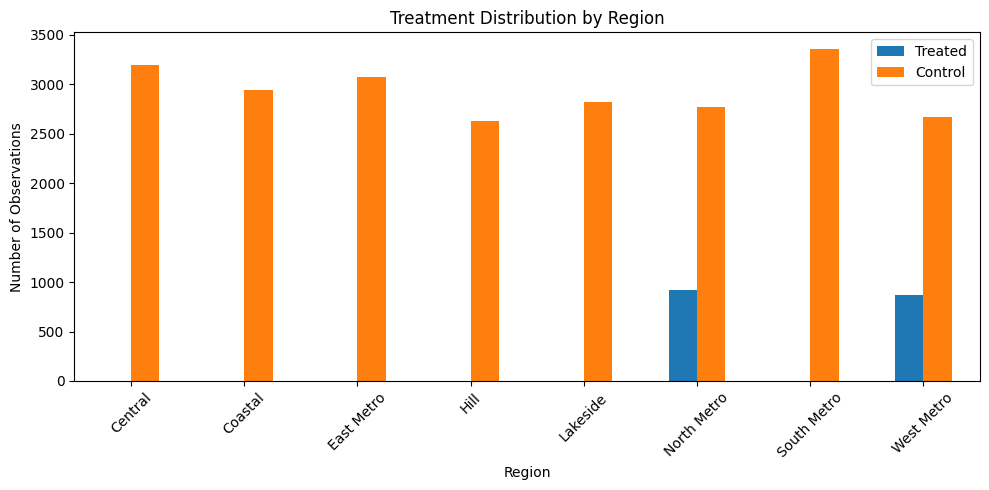

In [15]:
# Step 14: Treatment Distribution by Region

import matplotlib.pyplot as plt

region_treatment[['treated_rows', 'total_rows']].assign(
    control_rows=lambda x: x['total_rows'] - x['treated_rows']
)[['treated_rows', 'control_rows']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Treatment Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.legend(["Treated", "Control"])
plt.tight_layout()
plt.show()

In [16]:
# Step 15: Treatment vs Control Outcome Comparison

treatment_comparison = df.groupby('treatment').agg(
    average_revenue=('revenue', 'mean'),
    total_observations=('revenue', 'count'),
    average_demand=('demand_index', 'mean'),
    average_inventory=('inventory_level', 'mean')
)

display(treatment_comparison)

,average_revenue,total_observations,average_demand,average_inventory
treatment,,,,
0,124.384874,23446,1.050659,120.569649
1,126.604144,1788,1.116346,120.346756


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

adjustment_variables = [
    'demand_index',
    'inventory_level',
    'promotion_flag',
    'order_hour'
]

X = df[adjustment_variables]
y = df['treatment']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

propensity_model = LogisticRegression(max_iter=1000)
propensity_model.fit(X_scaled, y)

df['propensity_score'] = propensity_model.predict_proba(X_scaled)[:, 1]

print("Propensity Score Summary:")
print(df['propensity_score'].describe())

print("\nFirst 5 Propensity Scores:")
display(df[['treatment', 'propensity_score']].head())

Propensity Score Summary:
count    25234.000000
mean         0.070857
std          0.033482
min          0.016703
25%          0.045306
50%          0.063260
75%          0.088884
max          0.228292
Name: propensity_score, dtype: float64

First 5 Propensity Scores:


,treatment,propensity_score
0,0,0.104709
1,0,0.123385
2,0,0.112925
3,0,0.114330
4,0,0.118075


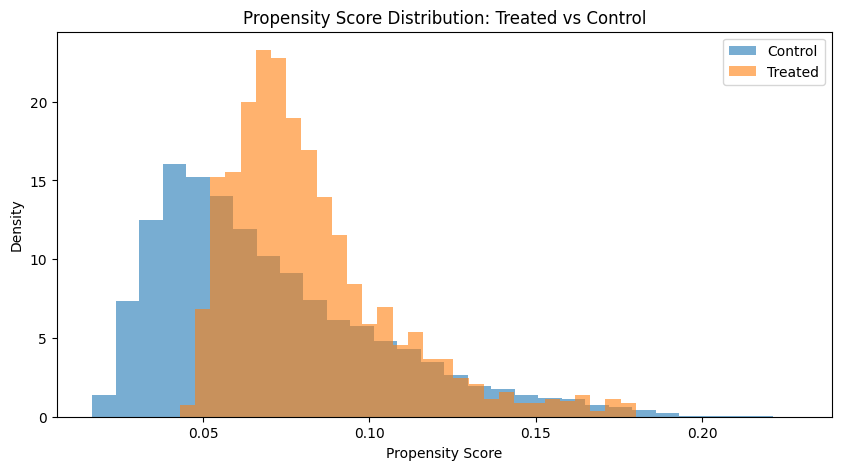

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df.loc[df['treatment'] == 0, 'propensity_score'],
    bins=30,
    alpha=0.6,
    label='Control',
    density=True
)

plt.hist(
    df.loc[df['treatment'] == 1, 'propensity_score'],
    bins=30,
    alpha=0.6,
    label='Treated',
    density=True
)

plt.xlabel('Propensity Score')
plt.ylabel('Density')
plt.title('Propensity Score Distribution: Treated vs Control')
plt.legend()
plt.show()

In [19]:
treated_min = df.loc[df['treatment'] == 1, 'propensity_score'].min()
treated_max = df.loc[df['treatment'] == 1, 'propensity_score'].max()

control_min = df.loc[df['treatment'] == 0, 'propensity_score'].min()
control_max = df.loc[df['treatment'] == 0, 'propensity_score'].max()

common_min = max(treated_min, control_min)
common_max = min(treated_max, control_max)

print("Treated Range:", treated_min, "to", treated_max)
print("Control Range:", control_min, "to", control_max)
print("Common Support Range:", common_min, "to", common_max)

print("\nObservations within Common Support:")
print(
    df['propensity_score'].between(common_min, common_max).sum()
)

Treated Range: 0.04301225260829097 to 0.17998867275531089
Control Range: 0.016703385622428662 to 0.22829227478611755
Common Support Range: 0.04301225260829097 to 0.17998867275531089

Observations within Common Support:
19708


In [20]:
common_df = df[
    df['propensity_score'].between(common_min, common_max)
].copy()

print("Original Dataset Shape:", df.shape)
print("Common Support Dataset Shape:", common_df.shape)

print("\nTreatment Distribution:")
print(common_df['treatment'].value_counts())

print("\nTreatment Proportion:")
print(common_df['treatment'].value_counts(normalize=True))

Original Dataset Shape: (25234, 33)
Common Support Dataset Shape: (19708, 33)

Treatment Distribution:
treatment
0    17920
1     1788
Name: count, dtype: int64

Treatment Proportion:
treatment
0    0.909275
1    0.090725
Name: proportion, dtype: float64


In [21]:
from sklearn.neighbors import NearestNeighbors

treated_df = common_df[common_df['treatment'] == 1].copy()
control_df = common_df[common_df['treatment'] == 0].copy()

nn = NearestNeighbors(n_neighbors=1, metric='euclidean')

nn.fit(control_df[['propensity_score']])

distances, indices = nn.kneighbors(
    treated_df[['propensity_score']]
)

matched_control = control_df.iloc[indices.flatten()].copy()

matched_treated = treated_df.copy()

matched_treated['match_distance'] = distances.flatten()
matched_control['match_distance'] = distances.flatten()

matched_df = pd.concat(
    [matched_treated, matched_control],
    ignore_index=True
)

print("Matched Dataset Shape:", matched_df.shape)

print("\nMatched Treatment Distribution:")
print(matched_df['treatment'].value_counts())

print("\nMatching Distance Summary:")
print(matched_df['match_distance'].describe())

Matched Dataset Shape: (3576, 34)

Matched Treatment Distribution:
treatment
1    1788
0    1788
Name: count, dtype: int64

Matching Distance Summary:
count    3.576000e+03
mean     3.490721e-06
std      6.673147e-06
min      0.000000e+00
25%      7.119794e-07
50%      1.741069e-06
75%      3.871594e-06
max      1.543407e-04
Name: match_distance, dtype: float64


In [22]:
balance_before = df.groupby('treatment')[adjustment_variables].mean().T

balance_after = matched_df.groupby('treatment')[adjustment_variables].mean().T

print("Balance Before Matching:")
display(balance_before)

print("\nBalance After Matching:")
display(balance_after)

print("\nAbsolute Mean Differences After Matching:")
display((balance_after[1] - balance_after[0]).abs())

Balance Before Matching:


treatment,0,1
demand_index,1.050659,1.116346
inventory_level,120.569649,120.346756
promotion_flag,0.150175,0.141499
order_hour,15.032372,14.791946



Balance After Matching:


treatment,0,1
demand_index,1.116552,1.116346
inventory_level,120.789150,120.346756
promotion_flag,0.141499,0.141499
order_hour,14.833893,14.791946



Absolute Mean Differences After Matching:


,0
demand_index,0.000205
inventory_level,0.442394
promotion_flag,0.000000
order_hour,0.041946


In [23]:
import numpy as np

def calculate_smd(data, variables):
    treated = data[data['treatment'] == 1]
    control = data[data['treatment'] == 0]

    results = {}

    for col in variables:
        mean_t = treated[col].mean()
        mean_c = control[col].mean()

        var_t = treated[col].var()
        var_c = control[col].var()

        pooled_sd = np.sqrt((var_t + var_c) / 2)

        results[col] = (
            (mean_t - mean_c) / pooled_sd
            if pooled_sd != 0 else 0
        )

    return pd.Series(results)

smd_before = calculate_smd(df, adjustment_variables)
smd_after = calculate_smd(matched_df, adjustment_variables)

balance_results = pd.DataFrame({
    'Before Matching': smd_before,
    'After Matching': smd_after
})

balance_results['Absolute SMD After'] = (
    balance_results['After Matching'].abs()
)

display(balance_results)

,Before Matching,After Matching,Absolute SMD After
demand_index,0.587173,-0.002514,0.002514
inventory_level,-0.009034,-0.017870,0.017870
promotion_flag,-0.024580,0.000000,0.000000
order_hour,-0.055385,-0.009651,0.009651


In [24]:

treated_revenue = matched_df[
    matched_df['treatment'] == 1
]['revenue'].mean()

control_revenue = matched_df[
    matched_df['treatment'] == 0
]['revenue'].mean()

ate = treated_revenue - control_revenue

print("Treated Average Revenue:", treated_revenue)
print("Control Average Revenue:", control_revenue)
print("Estimated ATE:", ate)

Treated Average Revenue: 126.60414429530202
Control Average Revenue: 126.05590044742728
Estimated ATE: 0.548243847874744


In [25]:

treated = matched_df[matched_df['treatment'] == 1]['revenue']
control = matched_df[matched_df['treatment'] == 0]['revenue']

difference = treated.mean() - control.mean()

se = np.sqrt(
    (treated.var() / len(treated)) +
    (control.var() / len(control))
)

lower_ci = difference - (1.96 * se)
upper_ci = difference + (1.96 * se)

print("Matched Difference:", difference)
print("Standard Error:", se)
print("95% Confidence Interval:", lower_ci, "to", upper_ci)

Matched Difference: 0.548243847874744
Standard Error: 3.4483839307456656
95% Confidence Interval: -6.2105886563867605 to 7.3070763521362485


In [26]:
region_results = matched_df.groupby('region_name').agg(
    average_revenue=('revenue', 'mean'),
    transaction_count=('revenue', 'count')
).reset_index()

display(region_results)

,region_name,average_revenue,transaction_count
0,Central,133.477507,341
1,Coastal,130.178855,131
2,East Metro,125.848247,251
3,Hill,141.523333,12
4,Lakeside,112.297015,67
5,North Metro,131.946289,1164
6,South Metro,119.818803,426
7,West Metro,121.409223,1184


In [27]:
region_treatment = matched_df.groupby(
    ['region_name', 'treatment']
)['revenue'].mean().unstack()

display(region_treatment)

treatment,0,1
region_name,,
Central,133.477507,NaN
Coastal,130.178855,NaN
East Metro,125.848247,NaN
Hill,141.523333,NaN
Lakeside,112.297015,NaN
North Metro,133.329057,131.579554
South Metro,119.818803,NaN
West Metro,121.625000,121.330668


In [28]:
region_treatment['difference'] = (
    region_treatment[1] - region_treatment[0]
)

display(region_treatment)

treatment,0,1,difference
region_name,,,
Central,133.477507,NaN,NaN
Coastal,130.178855,NaN,NaN
East Metro,125.848247,NaN,NaN
Hill,141.523333,NaN,NaN
Lakeside,112.297015,NaN,NaN
North Metro,133.329057,131.579554,-1.749503
South Metro,119.818803,NaN,NaN
West Metro,121.625000,121.330668,-0.294332


In [29]:
region_summary = matched_df.groupby(
    ['region_name', 'treatment']
).agg(
    average_revenue=('revenue', 'mean'),
    average_demand=('demand_index', 'mean'),
    average_inventory=('inventory_level', 'mean')
).reset_index()

display(region_summary)

,region_name,treatment,average_revenue,average_demand,average_inventory
0,Central,0,133.477507,1.085586,119.967742
1,Coastal,0,130.178855,1.043872,116.969466
2,East Metro,0,125.848247,1.059932,117.952191
3,Hill,0,141.523333,1.027717,112.750000
4,Lakeside,0,112.297015,1.021776,121.104478
5,North Metro,0,133.329057,1.227869,123.250000
6,North Metro,1,131.579554,1.138843,120.871739
7,South Metro,0,119.818803,1.110873,122.922535
8,West Metro,0,121.625000,1.170240,120.974684
9,West Metro,1,121.330668,1.092501,119.790323


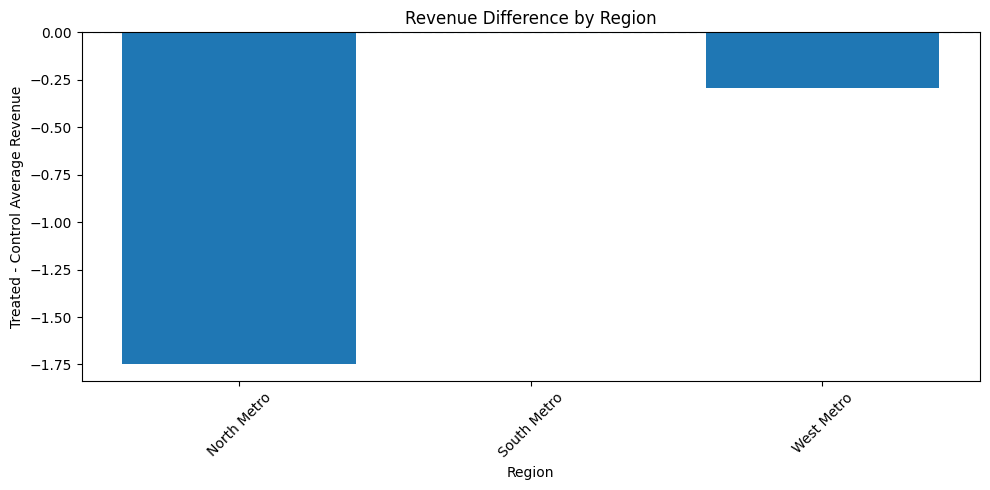

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    region_treatment.index,
    region_treatment['difference']
)

plt.axhline(0, linestyle='--')
plt.title('Revenue Difference by Region')
plt.xlabel('Region')
plt.ylabel('Treated - Control Average Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

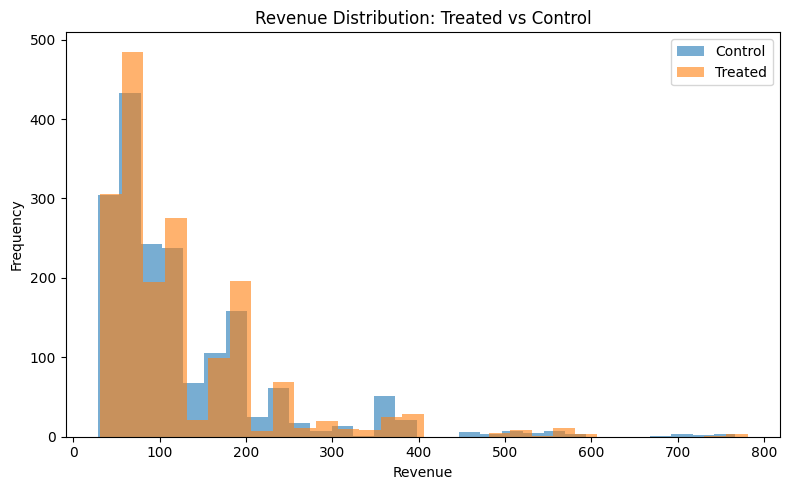

In [31]:
plt.figure(figsize=(8, 5))

plt.hist(
    matched_df[matched_df['treatment'] == 0]['revenue'],
    bins=30,
    alpha=0.6,
    label='Control'
)

plt.hist(
    matched_df[matched_df['treatment'] == 1]['revenue'],
    bins=30,
    alpha=0.6,
    label='Treated'
)

plt.title('Revenue Distribution: Treated vs Control')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
from scipy.stats import mannwhitneyu

treated_revenue = matched_df[
    matched_df['treatment'] == 1
]['revenue']

control_revenue = matched_df[
    matched_df['treatment'] == 0
]['revenue']

statistic, p_value = mannwhitneyu(
    treated_revenue,
    control_revenue,
    alternative='two-sided'
)

print("Mann-Whitney U Statistic:", statistic)
print("P-value:", p_value)

Mann-Whitney U Statistic: 1686682.5
P-value: 0.004270345872018295


/tmp/ipykernel_1513/1253637597.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


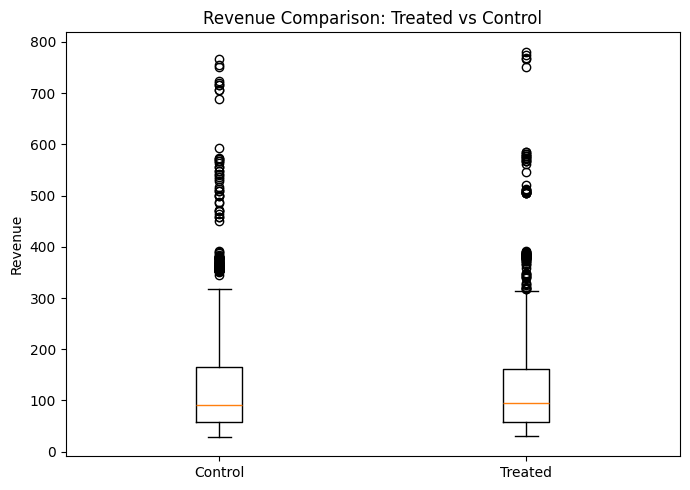

In [33]:
plt.figure(figsize=(7, 5))

plt.boxplot(
    [
        matched_df[matched_df['treatment'] == 0]['revenue'],
        matched_df[matched_df['treatment'] == 1]['revenue']
    ],
    labels=['Control', 'Treated']
)

plt.title('Revenue Comparison: Treated vs Control')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

In [34]:
sensitivity_results = matched_df.groupby('treatment')['revenue'].agg(
    ['mean', 'median', 'std', 'count']
)

display(sensitivity_results)

,mean,median,std,count
treatment,,,,
0,126.055900,91.245,105.583757,1788
1,126.604144,95.265,100.567426,1788


In [35]:
matched_df.to_csv(
    'week3_matched_analysis_results.csv',
    index=False
)

print("Matched analysis results saved successfully!")

Matched analysis results saved successfully!


In [36]:
region_summary.to_csv(
    'week3_region_comparison.csv',
    index=False
)

print("Regional comparison saved successfully!")

Regional comparison saved successfully!


In [37]:
balance_results.to_csv(
    'week3_matching_balance_results.csv',
    index=True
)

print("Matching balance results saved successfully!")

Matching balance results saved successfully!


In [38]:
region_treatment.to_csv(
    'week3_regional_treatment_differences.csv',
    index=True
)

print("Regional treatment differences saved successfully!")

Regional treatment differences saved successfully!


In [39]:
df.to_csv(
    'week3_propensity_score_analysis.csv',
    index=False
)

print("Propensity score analysis saved successfully!")

Propensity score analysis saved successfully!
